![alt text](../../pythonexposed-high-resolution-logo-black.jpg "Optionele titel")

### Grafieken maken met `mplfinance`

Een veelvoorkomende grafiek in financiën is een OHLC-grafiek, of kaarsgrafieken.

Dit type grafiek is niet beschikbaar in Matplotlib, maar de `mplfinance` add-on biedt dat type grafiek.
https://github.com/matplotlib/mplfinance

Als je dat pakket nog niet geïnstalleerd hebt in je virtuele omgeving, kan je het installeren met:
```
pip install mplfinance
```

In [ ]:
!pip install mplfinance

In [4]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import mplfinance as mpf

In [5]:
mpl.style.use('seaborn-v0_8-pastel')

We lezen gegevens in:

In [6]:
df = pd.read_csv('AAPL_data.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    1259 non-null   object 
 1   open    1259 non-null   float64
 2   high    1259 non-null   float64
 3   low     1259 non-null   float64
 4   close   1259 non-null   float64
 5   volume  1259 non-null   int64  
 6   Name    1259 non-null   object 
dtypes: float64(4), int64(1), object(2)
memory usage: 69.0+ KB


Aangezien al deze gegevens voor `AAPL` zijn, hebben we die `Name` kolom eigenlijk niet nodig.
Daarnaast wil ik de datums als index voor de rijen instellen - ik zou eerst de gegevens kunnen laden, vervolgens converteren naar datetime en dan de index instellen, maar we kunnen dit eigenlijk doen terwijl we de gegevens uit een csv-bestand laden.

Tot slot moeten de kolommen in de volgorde Open/Hoog/Laag/Slot/Volume zijn - dit maakt het makkelijker om te werken met mpf. Gelukkig is dat het geval in ons csv-bestand (anders zouden we gewoon fancy indexing kunnen gebruiken om de kolommen in de vereiste volgorde te selecteren).

In [7]:
data = pd.read_csv(
    'AAPL_data.csv', 
    usecols=['date', 'open', 'high', 'low', 'close', 'volume'],
    index_col=0,
    parse_dates=[0],  # geeft instructie aan Pandas om kolom 0 as dates te parsen
    skipinitialspace=True
)
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1259 entries, 2013-02-08 to 2018-02-07
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    1259 non-null   float64
 1   high    1259 non-null   float64
 2   low     1259 non-null   float64
 3   close   1259 non-null   float64
 4   volume  1259 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 59.0 KB


In [8]:
data

,open,high,low,close,volume
date,,,,,
2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416
2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425
2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363
2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995
2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154
...,...,...,...,...,...
2018-02-01,167.1650,168.6200,166.7600,167.7800,47230787
2018-02-02,166.0000,166.8000,160.1000,160.5000,86593825
2018-02-05,159.1000,163.8800,156.0000,156.4900,72738522


Gegeven dat onze index een DateTime-index is, en onze kolommen in de juiste volgorde Open/High/Low/Close/Volume staan, is het vrij eenvoudig om met `mpf` OHLC-grafieken te plotten.

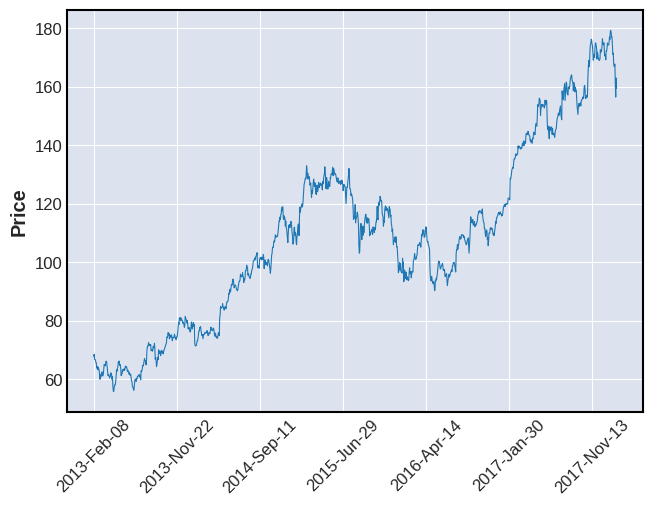

In [10]:
mpf.plot(data, type='line')

Er is nogal wat data om te plotten, en het is te 'samengeperst', dus ik zal slechts een subset van de data plotten, en de grafiek iets groter maken:

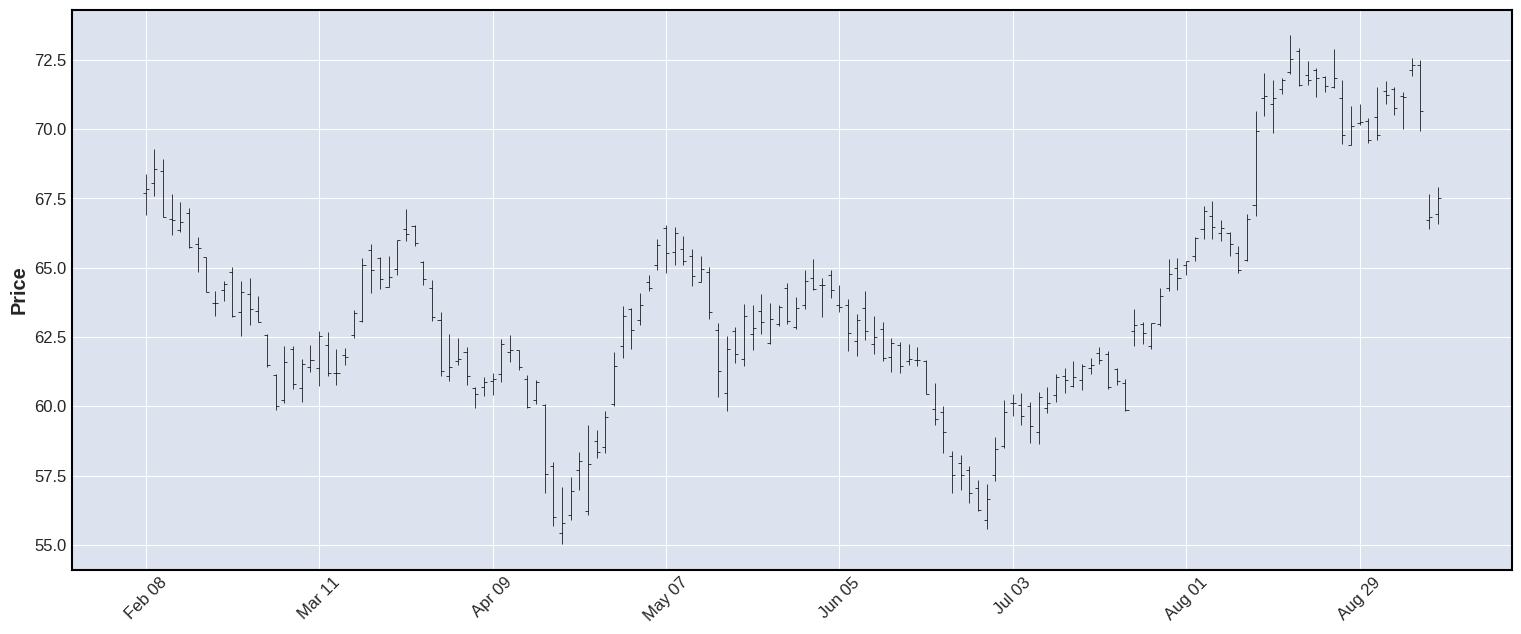

In [13]:
mpf.plot(data.iloc[:150], figsize=(20, 8)) # eerste 150 rijen

We kunnen de stijl van de grafiek veranderen:

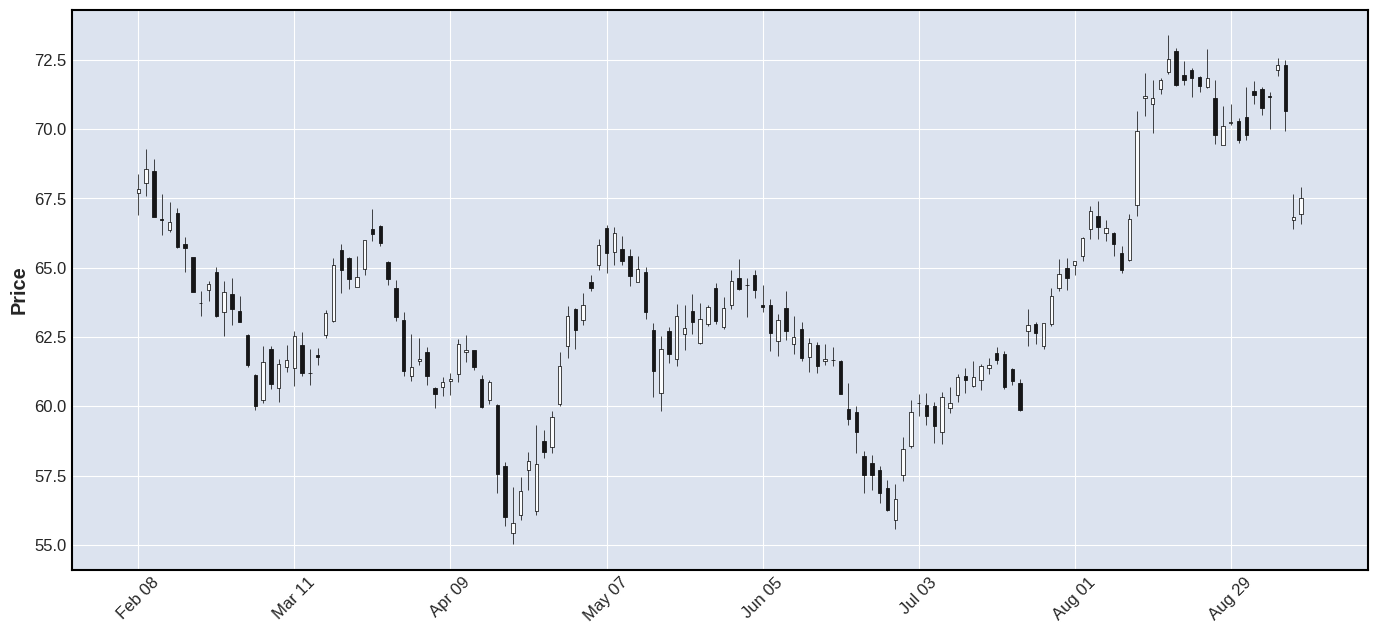

In [14]:
mpf.plot(data.iloc[:150], type='candle', figsize=(18, 8))

We kunnen zelfs heel gemakkelijk bewegende gemiddeldelijnen toevoegen:

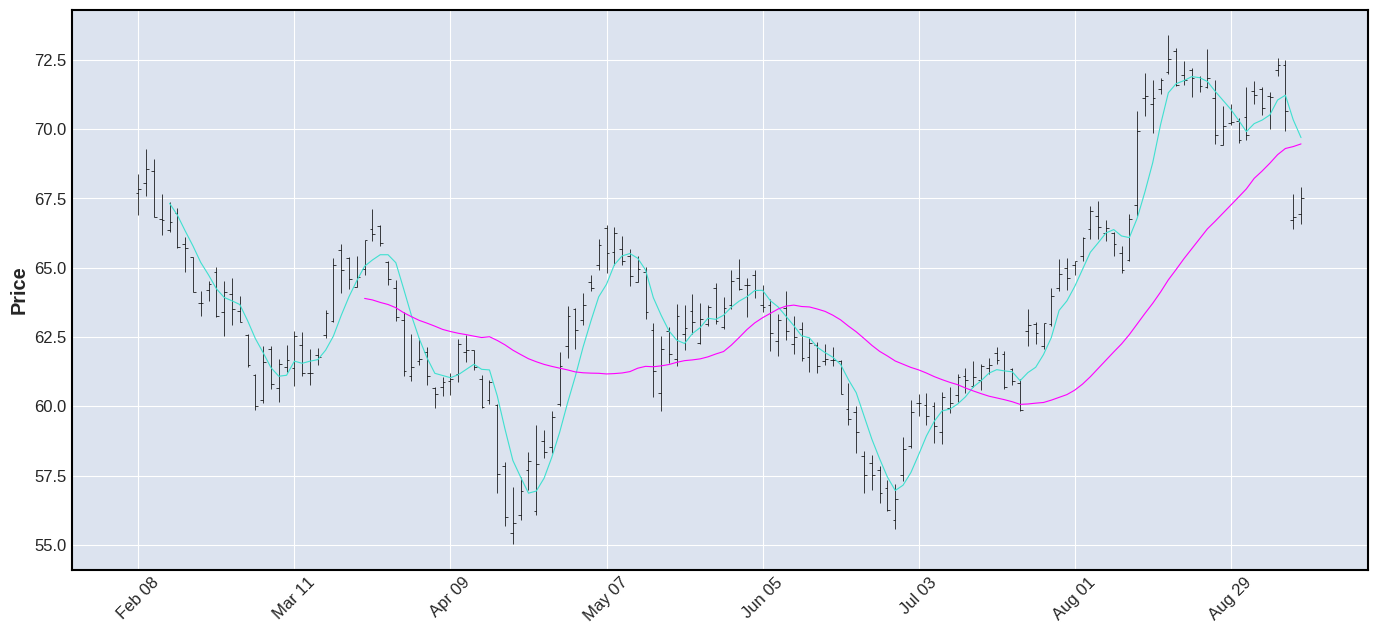

In [15]:
mpf.plot(data.iloc[:150], type='ohlc', mav=(5, 30), figsize=(18, 8))

Die eerste voortschrijdend gemiddelde is nauwelijks zichtbaar, dus we kunnen de kleuren aanpassen door een nieuwe `mplfinance`-stijl te maken waar we de `mavcolors` kunnen specificeren om doorheen te gaan bij het plotten van voortschrijdende gemiddelden.
Aangezien we geen volledig nieuwe stijl willen definiëren, gebruiken we een reeds bestaande stijl van Matplotlib en passen enkel aan wat we willen.

In [18]:
my_style = mpf.make_mpf_style(
    base_mpl_style='seaborn-v0_8-pastel',
    mavcolors=['blue', 'xkcd:gold', '#8E44AD']
)

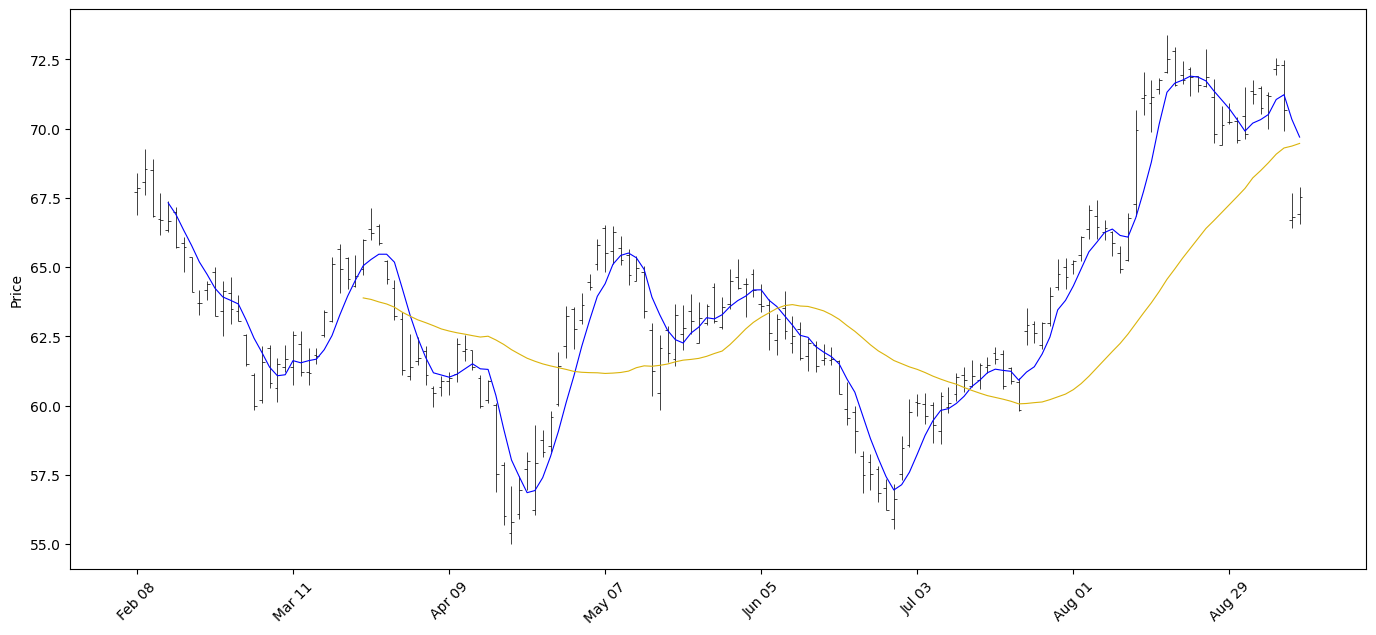

In [19]:
mpf.plot(
    data.iloc[:150], 
    type='ohlc', 
    mav=(5, 30), 
    figsize=(18, 8), 
    style=my_style
)

Je kunt kleuren definiëren met behulp van hexadecimale codes (zoals HTML-kleuren vaak gecodeerd zijn), of zelfs kleurenpaletten zoals XKCD (en andere).  

https://xkcd.com/color/rgb/

https://htmlcolorcodes.com/

We kunnen ook het Volume toevoegen als een tweede subplot en de niet-handelsdag 'gaten' tonen:

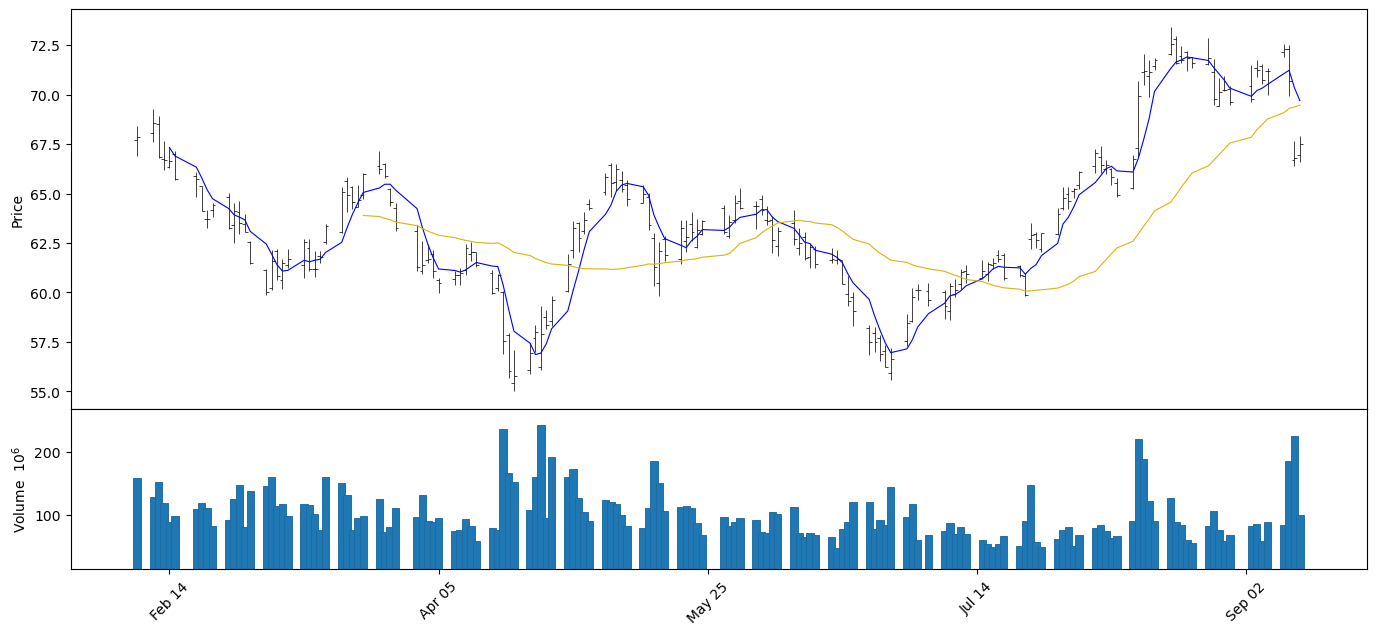

In [20]:
mpf.plot(
    data.iloc[:150], 
    type='ohlc', 
    mav=(5, 30), 
    volume=True, 
    show_nontrading=True, 
    figsize=(18, 8),
    style=my_style
)

We kunnen verdere aanpassingen maken aan de grafiek, zoals titels, aslabels, enzovoort:

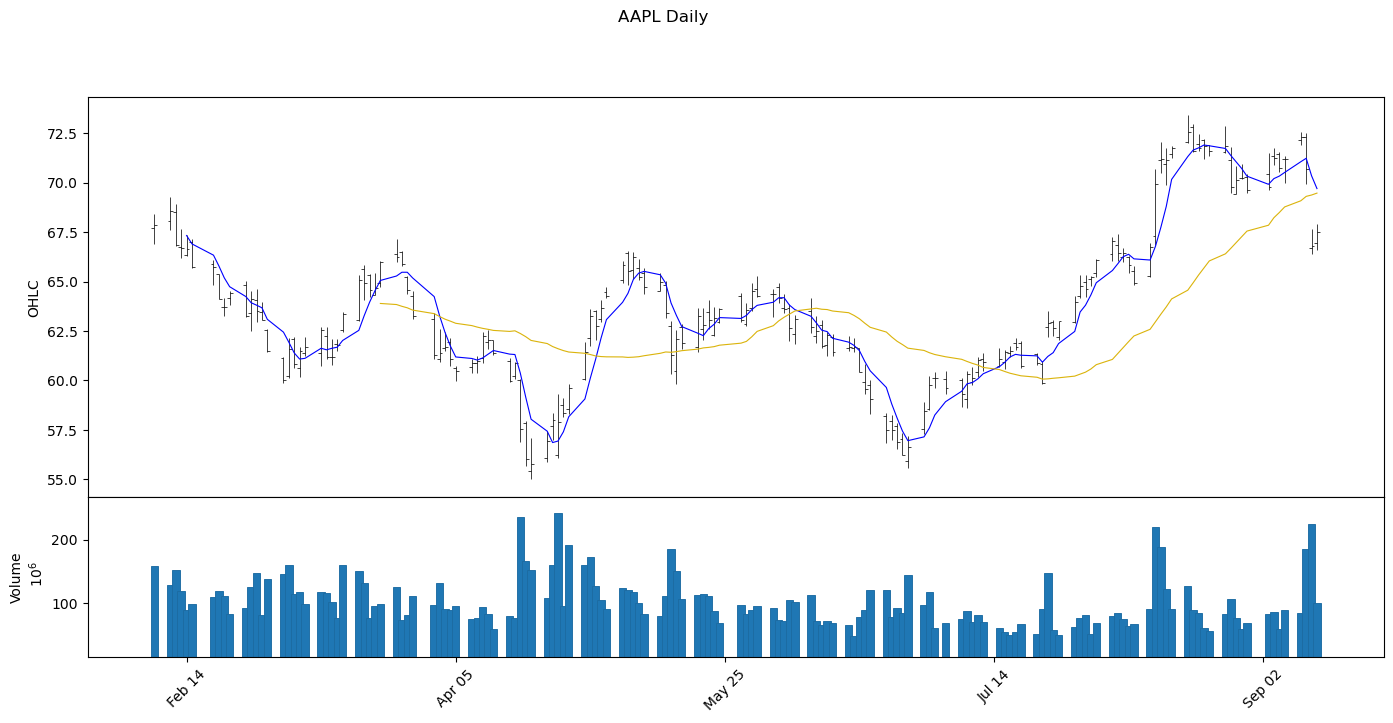

In [21]:
mpf.plot(
    data.iloc[:150], 
    type='ohlc', 
    mav=(5, 30), 
    volume=True, 
    show_nontrading=True, 
    title='AAPL Daily',
    ylabel='OHLC',
    ylabel_lower='Volume',
    figsize=(18, 8),
    style=my_style
)

We zouden ook extra grafieken kunnen toevoegen, zoals Bollinger bands (met de standaard periode van 20 en 2 standaardafwijkingen).  

Bollinger Bands zijn een technische analyse-instrument gecreëerd door John Bollinger in de vroege jaren '80. Ze bestaan uit drie lijnen die op een prijsgrafiek worden getekend:  


De Middenband is meestal een eenvoudig voortschrijdend gemiddelde (SMA) van de prijs over een bepaalde periode, vaak 20 dagen.  

De Bovenband wordt getekend op een bepaald aantal standaardafwijkingen (meestal twee) boven de middenband.  

De Onderband wordt getekend op een bepaald aantal standaardafwijkingen (ook meestal twee) onder de middenband.  

Het doel van Bollinger Bands is om relatieve hoogte- en laagtepunten van de prijs van een actief te bepalen. Wanneer de banden dicht bij elkaar liggen (de zogenaamde "squeeze"), suggereert dit een periode van lage volatiliteit en is een indicatie dat een volatiliteitsspike aanstaande kan zijn. Wanneer de banden uit elkaar wijken, duidt dit op een toegenomen volatiliteit in de markt.  


Traders gebruiken Bollinger Bands vaak in combinatie met andere technische indicatoren of analysevormen om koop- of verkoopsignalen te identificeren. Bijvoorbeeld, een veelgebruikte strategie is het kopen van een actief wanneer de prijs de onderband raakt en verkopen wanneer de prijs de bovenband bereikt, vooral als deze bewegingen gepaard gaan met andere bevestigende signalen.

In [24]:
period = 20
std = 2
data['ma20'] = data['close'].rolling(window=period).mean()
data['std20'] = data['close'].rolling(window=period).std()
data['upper'] = data['ma20'] + data['std20'] * std
data['lower'] = data['ma20'] - data['std20'] * std

data

,open,high,low,close,volume,ma20,std20,upper,lower
date,,,,,,,,,
2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,NaN,NaN,NaN,NaN
2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,NaN,NaN,NaN,NaN
2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,NaN,NaN,NaN,NaN
2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,NaN,NaN,NaN,NaN
2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2018-02-01,167.1650,168.6200,166.7600,167.7800,47230787,173.8700,3.920716,181.711431,166.028569
2018-02-02,166.0000,166.8000,160.1000,160.5000,86593825,173.2435,4.932542,183.108584,163.378416
2018-02-05,159.1000,163.8800,156.0000,156.4900,72738522,172.3180,6.167542,184.653084,159.982916


We maken eerst de extra subplots aan met enkel de kolommen die we willen (en dezelfde rijen als die we zullen gebruiken in de hoofdplot):

In [25]:
data[['upper', 'ma20', 'lower']].iloc[:150]

,upper,ma20,lower
date,,,
2013-02-08,NaN,NaN,NaN
2013-02-11,NaN,NaN,NaN
2013-02-12,NaN,NaN,NaN
2013-02-13,NaN,NaN,NaN
2013-02-14,NaN,NaN,NaN
...,...,...,...
2013-09-06,74.113325,70.481380,66.849435
2013-09-09,73.460825,70.850805,68.240785
2013-09-10,72.819451,71.045665,69.271879


In [26]:
bollinger = mpf.make_addplot(
    data[['upper', 'ma20', 'lower']].iloc[:150]
)

Dan voegen we ze toe aan de hoofdplot met behulp van het `addplot` argument:

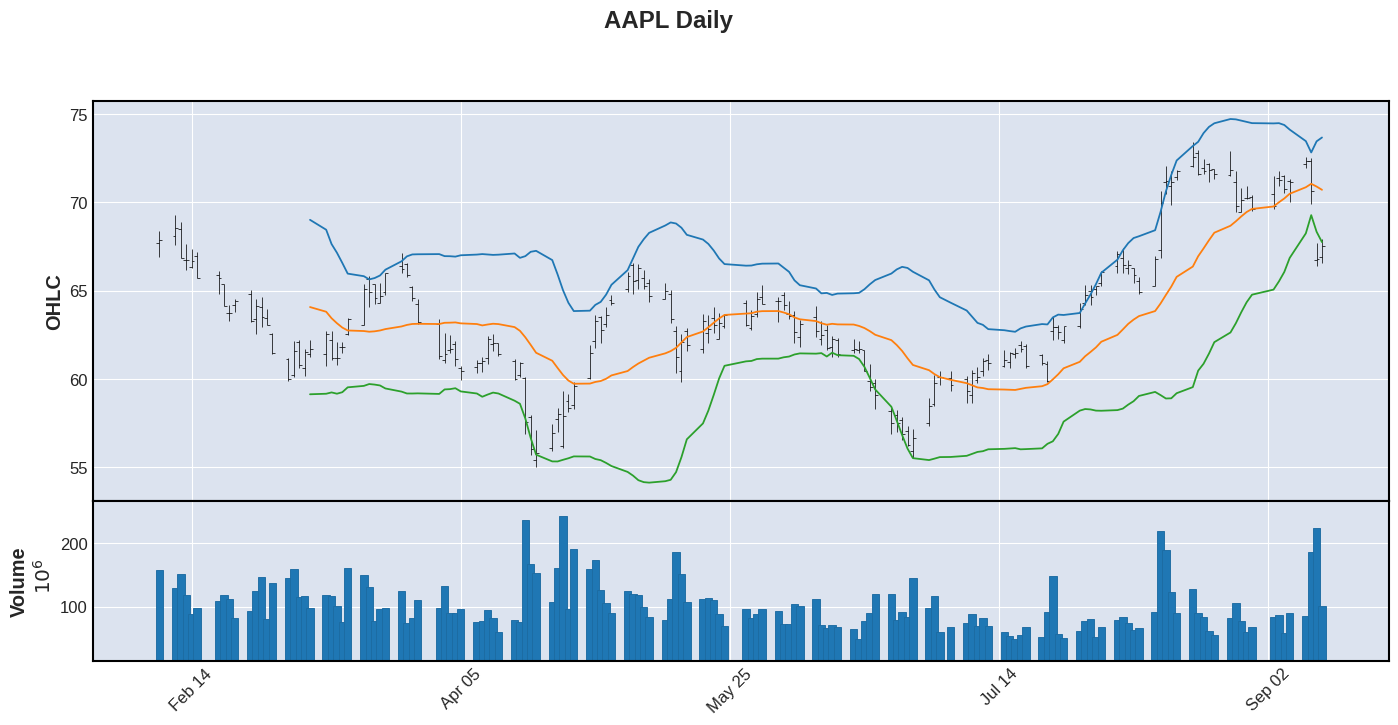

In [27]:
mpf.plot(
    data.iloc[:150], 
    addplot=bollinger,
    type='ohlc', 
    volume=True, 
    show_nontrading=True, 
    title='AAPL Daily',
    ylabel='OHLC',
    ylabel_lower='Volume',
    figsize=(18, 8)
)